# Petróleo e inflação no Brasil
**EAD6034 · Rafael Palazzi · Renan de Luca Avila**

**Pergunta:** a mesma alta inesperada de 10% no Brent tem resposta diferente no IPCA antes e depois de outubro de 2016?

**Como usar:** execute com **Shift+Enter**. As células 1 a 4 contam a história em cerca de cinco minutos; a célula 5 é o anexo com os demais itens do desafio. Para mudar um cenário, altere uma linha do painel e use **Restart Kernel and Run All Cells**; com `BOOT=99`, tudo roda em menos de meio minuto. Os números citados nos textos são da configuração de referência.

<details><summary>Todos os parâmetros: valores de referência, razões e efeitos das mudanças</summary>

Os parâmetros herdados também estão no dicionário `PARAMETROS`. Para mudar qualquer um, acrescente seu nome à chamada `PARAMETROS.update(...)` antes de `configurar`.

| Parâmetro | Valor de referência | Razão / efeito |
|---|---|---|
| `INICIO` | `"2004-01-01"` | Início da tarefa. Avançar reduz informação histórica. |
| `FIM` | `"2026-09-01"` | Fotografia dos dados. 2023-04-01 evita misturar a mudança de 2023. |
| `QUEBRA` | `"2016-10-01"` | Primeiro mês do segundo regime. Experimente 2018-01-01. |
| `ORDEM` | `["brent", "cambio", "ipa", "ipca", "selic"]` | Anteriores afetam posteriores no mesmo mês. |
| `ORDEM_ALT` | `["cambio", "brent", "ipa", "selic", "ipca"]` | Hipótese alternativa de reação no mês. |
| `P_FIXO` | `None` | None seleciona p. Inteiro força p: experimente 1, 2 ou 4. |
| `P_MAX` | `6` | Teto parcimonioso: 5 variáveis custam 25 coeficientes por lag. |
| `CRITERIO` | `"bic"` | BIC penaliza tamanho; "aic" ou "hq" permitem mais persistência. |
| `AJUSTAR_P_RESIDUOS` | `True` | Tenta p >= escolhido até passar Portmanteau, limitado a P_MAX. |
| `SAZONAIS` | `True` | 11 indicadores mensais. False deixa sazonalidade nos resíduos. |
| `DUMMIES` | `True` | Pulsos isolam episódios extremos sem apagar meses. |
| `MESES_ATIPICOS` | `["2018-05", "2018-06", "2020-03", "2020-04", "2020-05", "2020-06"]` | Lista de meses de greve/pandemia usada nos pulsos. |
| `EXCLUIR_2020` | `False` | Retira equações/defasagens que tocam 2020; não cola 2019 em 2021. |
| `DIFERENCIAR_SELIC` | `False` | Nível segue a aula. True testa sensibilidade à raiz unitária. |
| `INCLUIR_SELIC` | `True` | False estima o VAR sem a Selic, fonte da autocorrelação residual. |
| `RESTRICOES` | `{}` | Zeros nas defasagens. Ex.: `{"brent": ["cambio", "ipa", "ipca", "selic"]}`, Brent exógeno ao Brasil. |
| `H` | `24` | Horizonte IRF. Aumentar amplia incerteza e custo. |
| `H_REPASSE` | `12` | Acumulação h=0 até h=12, inclusive. |
| `CHOQUE_PCT` | `10.0` | Alta exata de 10%: impacto em log = 100*log(1.10). |
| `CONFIANCA` | `0.90` | Bandas pontuais como na aula. 0.95 alarga as bandas. |
| `BOOT` | `399` | Wild bootstrap: 99 para ensaio rápido, 999 para mais precisão. |
| `SEMENTE` | `20261025` | Reprodutibilidade. Mudar altera apenas erro Monte Carlo. |
| `ALFA` | `0.05` | Limiar dos testes, distinto de CONFIANCA das IRFs. |
| `LAG_DIAG` | `12` | Autocorrelação até um ano, sempre deve superar p. |
| `LAG_ARCH` | `4` | ARCH por equação: janela curta para limitar parâmetros. |
| `LAG_HAC` | `12` | Newey-West/Bartlett: autocovariâncias até 12 meses. |
| `CUSUM_INICIAL` | `36` | Aquecimento mínimo de 3 anos; maior valor atrasa o diagnóstico. |
| `REG_TESTES` | `"c"` | Constante, sem tendência nas taxas. "ct" admite tendência e muda H0. |
| `ADF_CRITERIO` | `"BIC"` | Escolhe lags do teste ADF, independentemente do critério do VAR. |
| `KPSS_LAGS` | `"auto"` | Largura automática; inteiro fixa a correção de dependência. |
| `MIN_GRAUS_LIVRES` | `10` | Margem mínima para estimar variância. Aumentar exige mais dados. |
| `THREADS` | `1` | Definido ao importar analise.py; altere lá antes de iniciar o kernel. Uma thread basta. |
| `ADF_MAX` | `12` | ADF até um ano, seleção BIC; KPSS usa largura automática. |
| `D_MAX` | `1` | Toda-Yamamoto: 1 lag extra não testado, admite variáveis I(1). |
| `JANELA` | `96` | Repasse móvel em 8 anos. Menor janela aumenta imprecisão. |
| `PASSO_JANELA` | `3` | Reestima a cada trimestre por velocidade; 1 gera curva mensal. |
| `FEVD_H` | `[1, 12, 24]` | h passos soma inovações de 0 a h-1, convenção da FEVD. |
| `EPISODIO` | `("2021-01-01", "2022-12-01")` | Episódio da decomposição histórica. |
| `INICIO_PREV` | `"2017-01-01"` | Primeira origem, treino até esse mês. Mais cedo amplia avaliação. |
| `H_PREV` | `[1, 12]` | Inflação DO MÊS t+h, não inflação acumulada dos h meses. |
| `SIM_N` | `600` | Observações simuladas; mais dados aproximam parâmetros verdadeiros. |
| `SIM_DESCARTE` | `200` | Aquecimento para reduzir influência da condição inicial. |
| `SIM_A` | `[[0.6, 0, -0.2], [0.15, 0.5, -0.1], [0.1, 0.2, 0.7]]` | Dinâmica conhecida, estável. |
| `SIM_P` | `[[1, 0, 0], [0.3, 0.7, 0], [0.5, 0.4, 0.6]]` | Impacto recursivo, zeros são hipóteses. |
| `PAUSAR` | `True` | Só no terminal. No notebook, a própria célula faz a pausa. |
| `MOSTRAR` | `True` | Só no terminal. O notebook força a exibição inline. |
| `PASTA_SAIDA` | `"resultados"` | Use resultados_teste para preservar os resultados de referência. |
| `EXIBIR_TUDO` | `False` | True também mostra nos passos 2 e 3 os itens secundários; o anexo sempre os mostra. |
| `DPI` | `150` | Qualidade PNG, sem efeito estatístico. |
| `FONT_SIZE` | `11` | Letras dos gráficos, sem efeito estatístico. |
| `MAX_LINHAS_TELA` | `24` | Limita tabelas longas em cada saída; CSV sempre contém tudo. |
| `CASAS` | `4` | Arredondamento na tela; CSV mantém precisão. |
| `TOL` | `1e-8` | Tolerância numérica das checagens, não significância. |

</details>

In [1]:
from copy import deepcopy
import analise as var
%matplotlib inline

PARAMETROS = deepcopy(var.PARAMETROS_PADRAO)
PARAMETROS.update(
    P_FIXO=None,                 # None: o BIC escolhe p (dá 2). Ex.: 4.
    CRITERIO="bic",              # "aic" ou "hq" aceitam mais defasagens.
    QUEBRA="2016-10-01",         # Primeiro mês do regime "depois". Ex.: "2018-01-01".
    FIM="2026-09-01",            # Ex.: "2023-04-01", antes da nova estratégia da Petrobras.
    ORDEM=["brent", "cambio", "ipa", "ipca", "selic"],  # Quem reage no mesmo mês.
    CHOQUE_PCT=10.0,             # Alta inicial do Brent ou do câmbio, em %.
    H_REPASSE=12,                # Soma do mês 0 até o mês 12.
    BOOT=399,                    # 99 para ensaios rápidos.
    CONFIANCA=0.90,              # 0.95 alarga as bandas.
    EXCLUIR_2020=False,          # True retira 2020 e as equações que o usam nas defasagens.
    DIFERENCIAR_SELIC=False,     # True usa a variação mensal da Selic.
    INCLUIR_SELIC=True,          # False estima o VAR sem a Selic.
    RESTRICOES={},               # Ex.: {"brent": ["cambio", "ipa", "ipca", "selic"]}.
    EXIBIR_TUDO=False,           # True mostra também as tabelas secundárias.
    PASTA_SAIDA="resultados",    # "resultados_teste" preserva a referência.
)
var.configurar(PARAMETROS, notebook=True)

## 2. Dados e modelo
Brent e câmbio entram como 100×Δlog; IPA e IPCA já são taxas mensais; a Selic entra em nível. Estimamos um VAR para **jan/2004–set/2016** e outro para **out/2016–set/2026**, com o mesmo p.

**O que olhar:** o BIC escolhe **p=2** e o raio < 1 indica sistema estável. O Portmanteau rejeita ausência de autocorrelação, mas a coluna **LB_p** mostra que só a equação da **Selic** falha; Brent, câmbio, IPA e IPCA passam.

### 1. Dados: 5 séries mensais, públicas e salvas no repositório

01/2004 a 09/2026: 273 meses. Ordem: ['brent', 'cambio', 'ipa', 'ipca', 'selic']


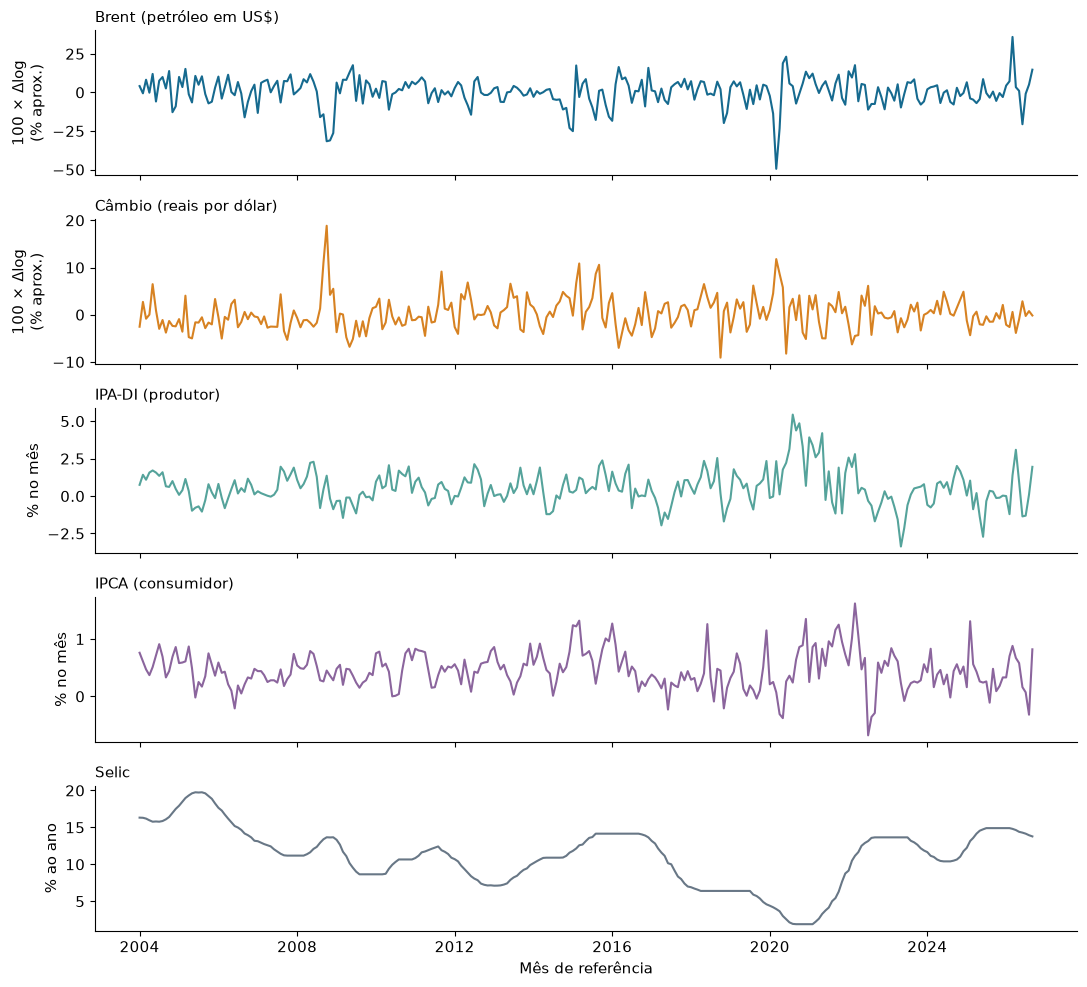

**01 estacionariedade**

,ADF_p,KPSS_p
serie,,
brent,0.0000,0.10
cambio,0.0000,0.10
ipa,0.0000,0.10
ipca,0.0000,0.10
selic,0.0745,0.03
log_Brent_nivel,0.0044,0.10
log_cambio_nivel,0.8762,0.01


ADF: H0 raiz unitária. KPSS: H0 estacionariedade. P-valores de fronteira são limites.


### 2. Escolha de p, resíduos e estabilidade dinâmica

**02 defasagens**

,aic,bic,hq,p_autocorr
p,,,,
1,1.3335,2.8786,1.9542,0.0
2,0.3463,2.2273,1.1019,0.0
3,0.2689,2.4857,1.1594,0.0
4,0.3237,2.8764,1.3491,0.0
5,0.3092,3.1978,1.4695,0.0
6,0.4012,3.6257,1.6965,0.0


**02 residuos completa**

,LB_p,JB_p,ARCH_p
brent,0.5817,0.0022,0.0150
cambio,0.2082,0.0000,0.0543
ipa,0.2472,0.0919,0.0001
ipca,0.6884,0.0000,0.2169
selic,0.0000,0.0000,0.0000


**02 diagnostico**

,n,k_por_eq,p,raio,meia_vida,Portmanteau_p
amostra,,,,,,
completa,271,28,2,0.9127,7.5852,0.000
antes,151,22,2,0.9199,8.3056,0.002
depois,118,28,2,0.9224,8.5844,0.000


Meia-vida: modo dominante, não necessariamente a meia-vida de cada IRF.
RESSALVA: autocorrelação residual. Bootstrap e p-valores exigem cautela; teste outro p.
Equações com Ljung-Box <= ALFA: completa: ['selic'], antes: ['selic'], depois: ['selic']


In [2]:
# Séries, raiz unitária, escolha de p e diagnósticos dos resíduos.
dados = var.carregar_dados()
modelo, regimes, diagnostico = var.estimar_modelos(dados)

## 3. O experimento: +10% no Brent, uma única vez
No mês 0, o Brent em US$ sobe 10% de surpresa. As demais surpresas são zero; as outras variáveis reagem pelo modelo. Em cada regime, comparamos o IPCA com e sem a surpresa e somamos do mês 0 ao 12. O painel da direita é outro experimento: +10% no câmbio, que **não** aumenta depois de 2016 (+0,25 → −0,49, instável entre variantes).

**Leitura:** +0,07 p.p. antes e +0,41 p.p. depois; diferença **+0,34 p.p.**, banda de 90% [+0,10; +0,58]. Cerca de um terço da resposta posterior aparece **no próprio mês** (`impacto_h0`: +0,145 depois, −0,005 antes).

### 3. Experimento: resposta do IPCA ao Brent e ao câmbio, antes e depois da quebra

antes 399 réplicas; 0.0% com raiz >= 1


depois 399 réplicas; 0.3% com raiz >= 1


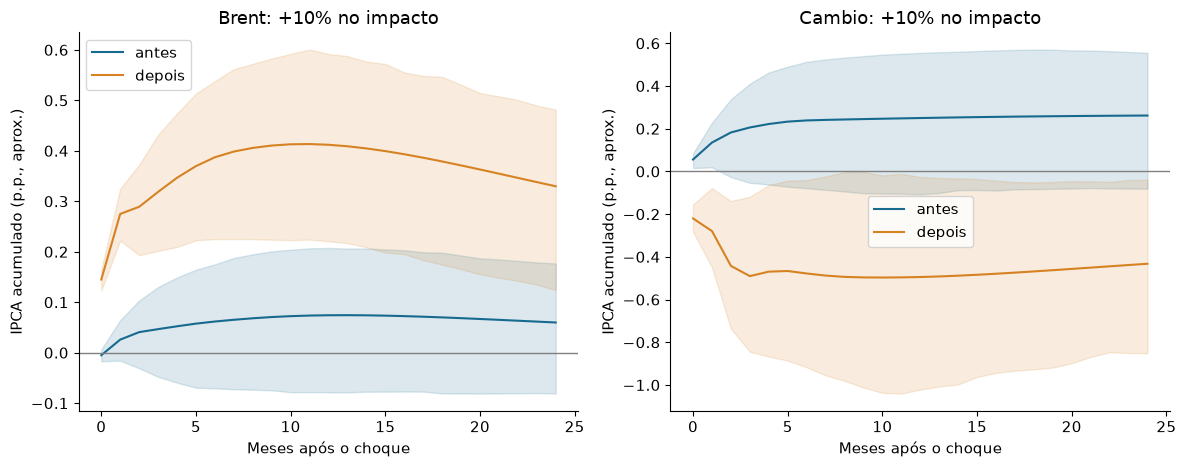

**04 respostas 12m**

,choque,amostra,resposta,inferior,superior,impacto_h0,corr_residuo_ipca
0,brent,antes,0.0742,-0.0783,0.2076,-0.0050,-0.0227
1,brent,depois,0.4120,0.2209,0.5918,0.1450,0.4204
2,cambio,antes,0.2501,-0.1073,0.5550,0.0560,0.0949
3,cambio,depois,-0.4944,-1.0217,-0.0262,-0.2201,-0.2795


impacto_h0: resposta no próprio mês do choque, já incluída na soma até h=12.


**04 diferenca**

,depois_menos_antes,inferior,superior
brent,0.3378,0.1003,0.5757
cambio,-0.7445,-1.3330,-0.1389


Compare a banda da DIFERENÇA com zero. Sobreposição de bandas separadas não é um teste.
origem_acumulada: 100×log da própria origem em h=12. Mesmo choque inicial, trajetórias diferentes.


In [3]:
# Mesmo choque nos dois regimes, com banda bootstrap da diferença.
choques = var.comparar_choques(regimes)

## 4. O que resiste e o que depende das hipóteses
**Política ou correlação dos resíduos?** Trocando uma peça de cada vez entre os regimes, só as defasagens mudam a resposta em −0,04 a +0,08 p.p.; só a covariância dos resíduos, em +0,26 a +0,38. A mudança está **no mesmo mês**: a correlação das surpresas de Brent e IPCA vai de −0,02 para +0,42. O teste focalizado nessa relação usa **uma** restrição, contra 55 do Chow do sistema, e rejeita com p=0,0001. Por isso o resultado depende de o Brent vir antes do IPCA: com o IPCA antes, cai para 0,03–0,10.

**Variantes** (cerca de 45 s; explique enquanto roda): a diferença é **positiva nas 13 variantes de especificação e amostra, de +0,20 a +0,38 p.p.** A banda exclui zero em 10 e inclui zero com p=4 e com fim em 12/2025 ou 12/2021. Sem pulsos, +0,35; com o câmbio antes do Brent, +0,28; com o Brent exógeno, +0,33.

### 4. Identificação: 120 ordens e mesmo mês versus defasagens

**05 mudanca 120 ordens**

,min_delta,max_delta,fracao_delta_positivo,base,quantil_base,min_IPCA_antes,max_IPCA_antes
brent,0.0338,0.3378,1.0,0.3378,1.00,0.0338,0.1001
cambio,-0.8077,-0.1913,0.0,-0.7445,0.35,-0.3249,-0.1913


quantil_base = fração das ordens com diferença <= base; 1 indica a ordem-base no topo do envelope.
IPCA_antes: ordens com o IPCA antes da origem do choque, isto é, sem repasse no mesmo mês.


**05 impacto vs propagacao**

Sigma_antes  Sigma_depois
choque A_defasagens                           
brent  antes              0.0742        0.4498
       depois             0.1520        0.4120
cambio antes              0.2501       -0.2848
       depois            -0.1131       -0.4944

... (2 outputs left out)

Mesmo mês: resíduo do IPCA sobre o do Brent, com interação pós-quebra. Uma restrição; o Chow do sistema testa 55.
Brent: trocar só Sigma muda +0.260 a +0.376 p.p.; trocar só A, -0.038 a +0.078 p.p.


### 5. Variantes: o sinal, a magnitude e a banda resistem? (15 especificações)

**10 variantes**

,grupo,p,brent_diferenca,brent_inferior,brent_superior
variante,,,,,
Base: painel atual,Referência,2,0.3378,0.1003,0.5757
p = 1,Defasagens,1,0.3016,0.1113,0.4344
p = 4,Defasagens,4,0.1982,-0.0811,0.4892
Selic em diferença,Selic,1,0.3465,0.1190,0.5540
Sem a Selic (4 variáveis),Selic,1,0.3806,0.1940,0.5739
Sem pulsos de 2018 e 2020,Episódios,2,0.3527,0.1204,0.5578
Excluir 2020,Episódios,2,0.3209,0.0280,0.5237
Pulsos: corte do ICMS 07-08/2022,Episódios,2,0.3815,0.1337,0.6364
Pulsos: tarifaço 01-03/2015,Episódios,2,0.2727,0.0450,0.4915


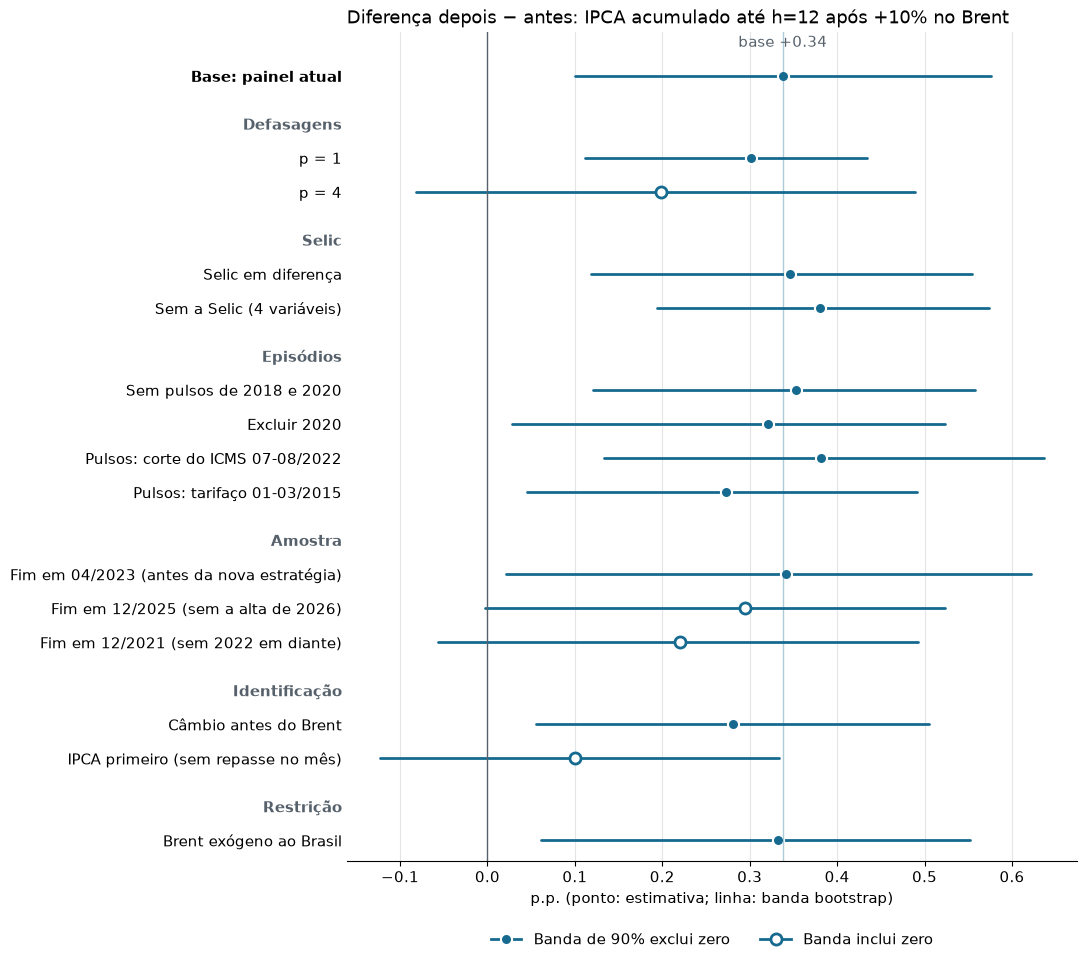

Brent, 13 especificações: diferença positiva em 13, de 0.20 a 0.38 p.p.; banda de 90% exclui zero em 10.
Identificação muda a pergunta: IPCA primeiro proíbe o repasse no mês e mostra o peso do impacto imediato.
Câmbio: compare magnitude e banda entre linhas; a instabilidade impede leitura estrutural.


In [4]:
# Ordens dos choques, mesmo mês versus defasagens, e 15 variantes.
ident = var.identificacao(regimes)
tabela_variantes = var.variantes()

## Conclusão: as três perguntas
1. **O repasse aumentou?** O do Brent, sim: mais forte e mais rápido, +0,34 p.p. O do câmbio, não.
2. **Chow:** 55 restrições no sistema, 11 por equação; o poder se dilui e o teste não olha a correlação dos resíduos. O teste de uma restrição no mesmo mês rejeita com p=0,0001; o OLS-CUSUM do `vars::stability()` não rejeita.
3. **Política ou correlação:** a mudança vem da correlação no mesmo mês, não das defasagens. É compatível com reajustes mais frequentes, mas o VAR recursivo não a separa de choques comuns. A comparação **não isola** o efeito causal da Petrobras.

## 5. Anexo: demais exigências do desafio
Itens secundários dos passos 2 e 3, Granger (Toda–Yamamoto, usual e HAC), envelope das 120 ordens, FEVD, Chow, CUSUM recursivo e OLS-CUSUM, repasse em janela móvel, decomposição histórica, simulação e previsão (VAR, AR, RW, DM e Clark–West). Grava a síntese em `resultados/resumo.json`. Cerca de 15 segundos.

### A1. Itens secundários dos passos 2 e 3: resíduos por regime, raízes, ciclos e razões

**02 residuos antes**

,LB_p,JB_p,ARCH_p
brent,0.2382,0.1179,0.1681
cambio,0.1809,0.0010,0.0274
ipa,0.2009,0.5738,0.0996
ipca,0.3604,0.3051,0.3312
selic,0.0003,0.1401,0.9280


**02 residuos depois**

,LB_p,JB_p,ARCH_p
brent,0.2902,0.0000,0.3971
cambio,0.3144,0.0242,0.6137
ipa,0.3185,0.9764,0.2542
ipca,0.8918,0.0008,0.8848
selic,0.0000,0.0000,0.0348


**02 ciclos**

,modulo,periodo_meses
0,0.9127,218.0132
1,0.4445,4.5636
2,0.2012,2.9401
3,0.5087,98.7917


**02 raizes**

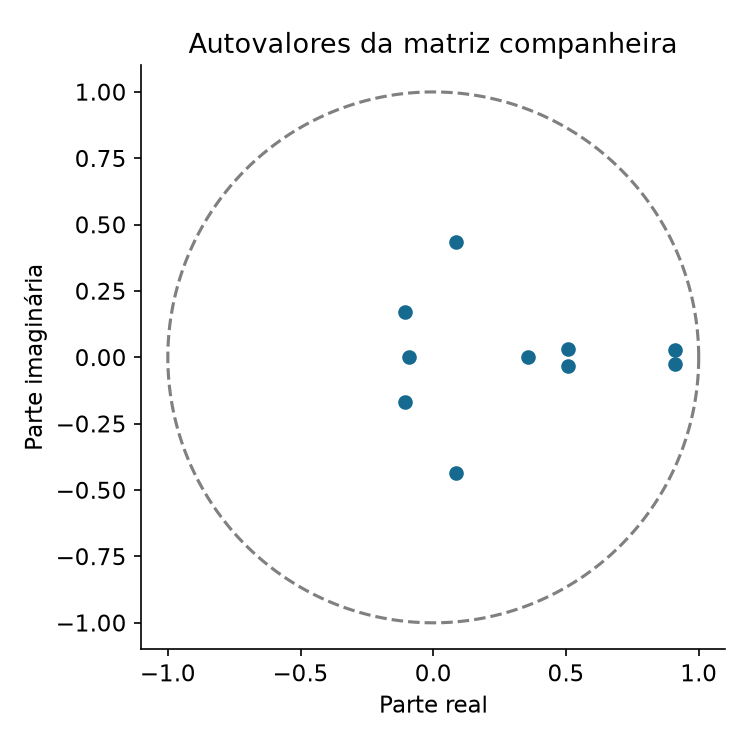

**04 razao antes**

,elasticidade_aprox,inferior,superior,denominador_cruza_zero,origem_acumulada
brent,0.0053,-0.0059,0.0166,False,14.1028
cambio,0.0193,-0.0081,0.0434,False,12.9865


**04 razao depois**

,elasticidade_aprox,inferior,superior,denominador_cruza_zero,origem_acumulada
brent,0.0409,0.0242,0.0601,False,10.0724
cambio,-0.0581,-0.1119,-0.0033,False,8.5048


### A2. Granger condicional, usual e robusto HAC

**03 granger**

,causa,destino,Wald_usual_p,Wald_HAC_p
0,brent,cambio,0.0871,0.2159
1,brent,ipa,0.0023,0.0096
2,brent,ipca,0.0410,0.0107
3,brent,selic,0.2012,0.1031
4,cambio,brent,0.0021,0.0222
5,cambio,ipa,0.0141,0.0017
6,cambio,ipca,0.0953,0.2174
7,cambio,selic,0.5731,0.5054
8,ipa,brent,0.3674,0.2039
9,ipa,cambio,0.0099,0.0001


VAR aumentado p+dmax=3; testamos p=2. dmax=1 deve cobrir a integração.


### A3. Envelope de 120 ordens na amostra completa, correlação residual e FEVD

**05 correlacao residuos**

,brent,cambio,ipa,ipca,selic
brent,1.0000,-0.2992,0.2436,0.1657,-0.0661
cambio,-0.2992,1.0000,0.1951,-0.0862,-0.0722
ipa,0.2436,0.1951,1.0000,0.2860,0.0450
ipca,0.1657,-0.0862,0.2860,1.0000,0.1192
selic,-0.0661,-0.0722,0.0450,0.1192,1.0000


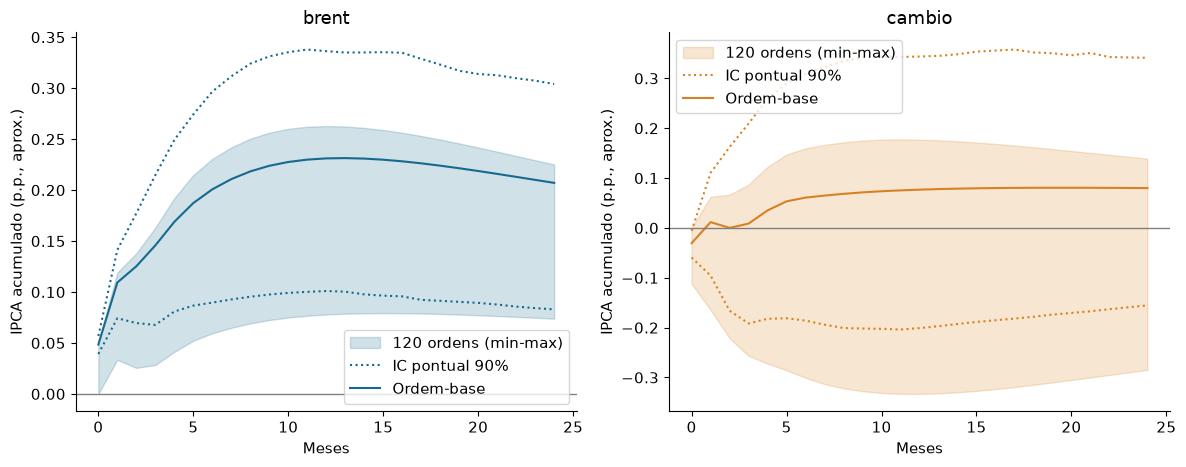

Envelope: sensibilidade à identificação, NÃO intervalo de confiança.


**05 fevd ipca**

,ordem,h,brent,cambio,ipa,ipca,selic
0,base,1,2.7448,0.1476,7.6292,89.4783,0.0000
1,base,12,6.6185,0.4538,16.7644,72.3934,3.7699
2,base,24,6.5593,0.4473,16.6532,71.4180,4.9221
3,alternativa,1,2.1489,0.7436,7.6292,88.4510,1.0273
4,alternativa,12,6.4529,0.6194,16.7644,70.6262,5.5371
5,alternativa,24,6.3925,0.6142,16.6532,69.6006,6.7395


### A4. Chow na data conhecida, CUSUM e repasse móvel

**06 chow**

,Chow_F_p,Wald_HAC_p
equacao,,
brent,0.4679,0.1163
cambio,0.0115,0.0027
ipa,0.0357,0.0008
ipca,0.0227,0.0010
selic,0.8422,0.2918


... (2 outputs left out)

OLS-CUSUM de Ploberger-Krämer, padrão de vars::stability() no R. H0: coeficientes estáveis.


**06 quebra conjunta**

,LR,restricoes,p_assintotico
0,91.8461,55,0.0013


11 restrições/equação; 55 no sistema. LR supõe covariância comum; inferência exploratória em níveis.


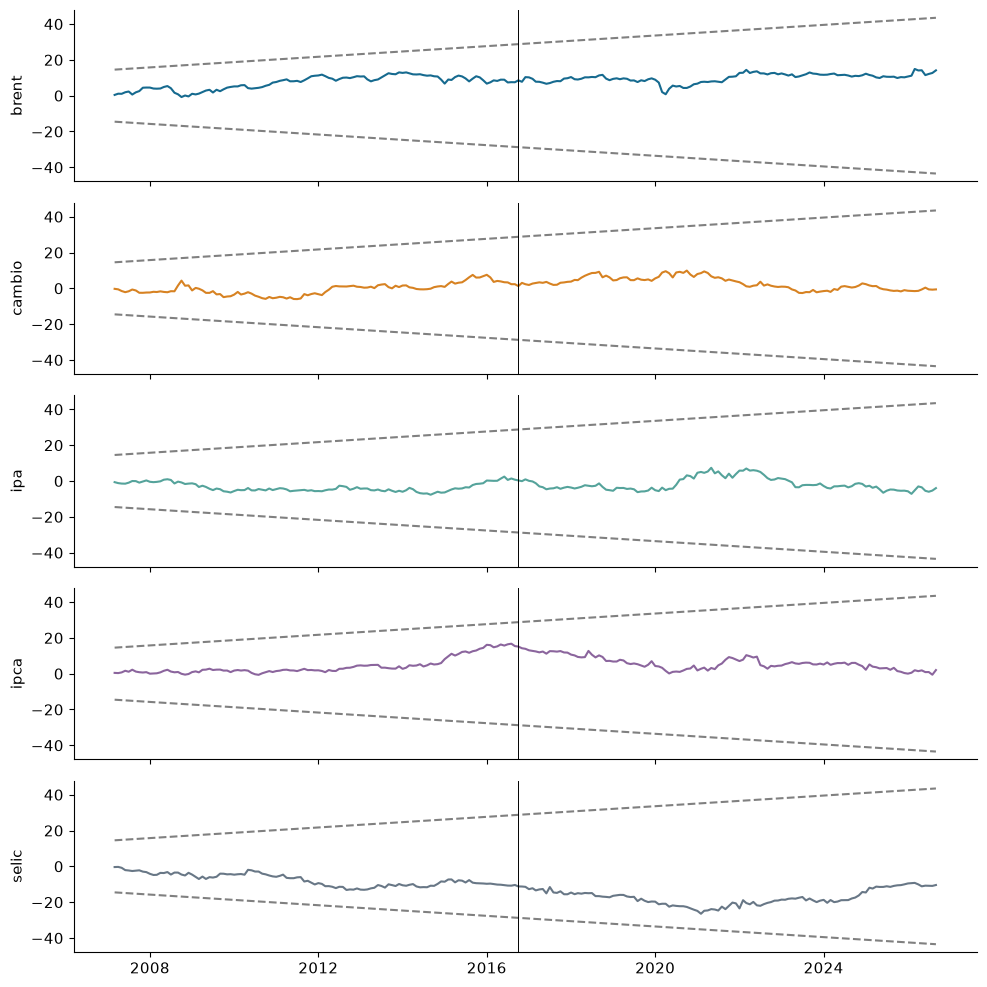

**06 repasse movel**

,brent,cambio,raio
data,,,
2011-12-01,0.0219,-0.0011,0.9231
2012-03-01,0.0230,-0.0026,0.9247
2012-06-01,0.0184,-0.0213,0.9293
2012-09-01,0.0169,-0.0067,0.8833
2012-12-01,0.0179,-0.0041,0.8789
2013-03-01,0.0149,0.0007,0.8593
2013-06-01,0.0152,0.0023,0.8581
2013-09-01,0.0099,0.0090,0.8776
2013-12-01,0.0108,0.0094,0.8830


[Linhas intermediárias omitidas na tela; arquivo CSV completo.]


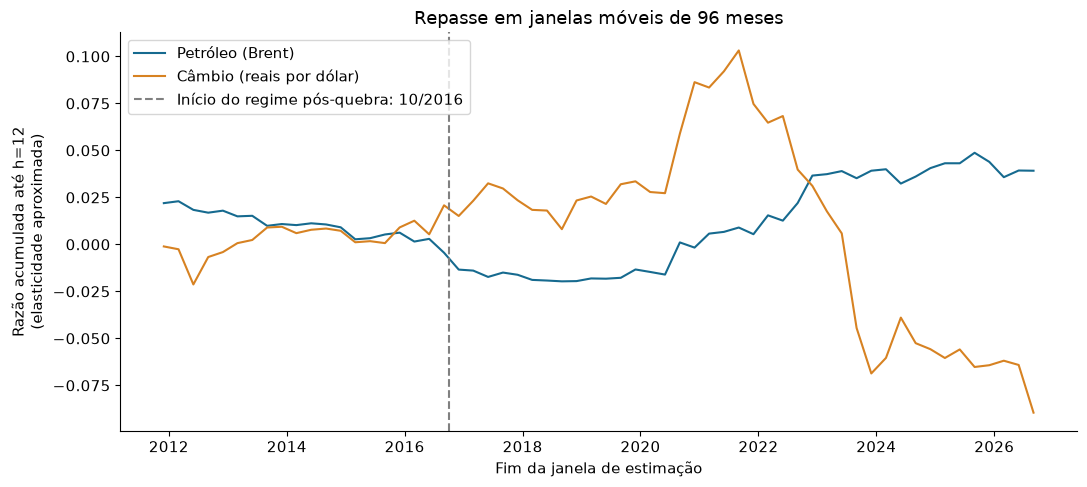

CUSUM sem pulsos: episódios extremos também podem provocar rejeição. Janelas se sobrepõem.


### A5. Decomposição histórica, com conferência exata da soma

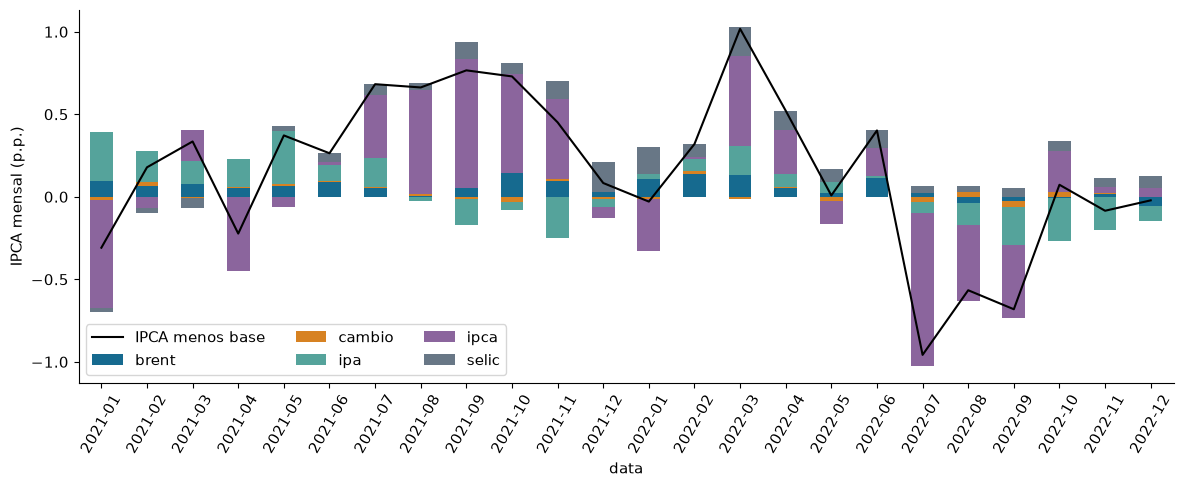

Erro máximo de reconstrução: 1.12e-13. Base: constante, calendário, pulsos e condições iniciais.


### A6. Simulação com dinâmica e impactos conhecidos

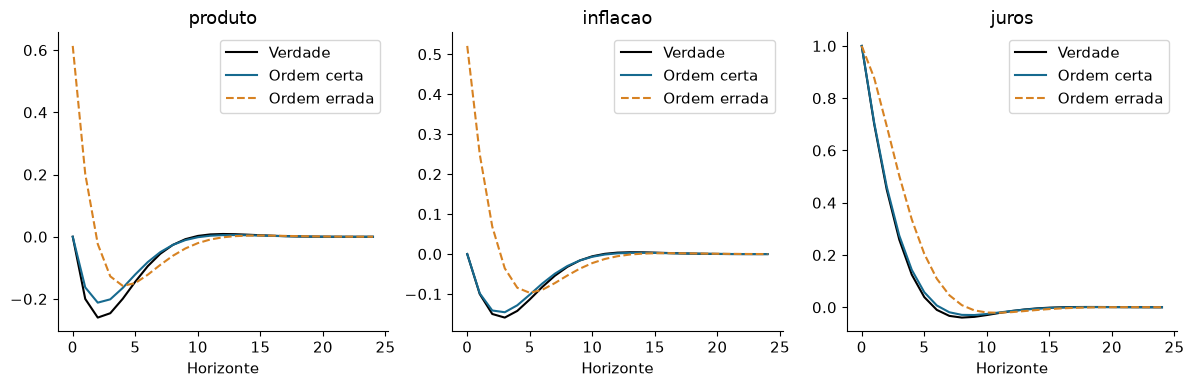

Ordem correta mais próxima nesta simulação: True


**08 simulacao**

,RMSE_IRF
certa,0.0116
errada,0.1328


### A7. Previsão em janela expansiva: VAR contra AR e passeio aleatório

**09 metricas**

,h,modelo,n,RMSE,MAE,DM_VAR_vs_modelo_p,CW_favor_VAR_p
0,1,VAR,116,0.3335,0.2509,NaN,NaN
1,1,AR,116,0.3466,0.2570,NaN,0.0003
2,1,RW,116,0.4112,0.3078,NaN,NaN
3,1,Sazonal,116,0.5060,0.3817,0.0045,NaN
4,12,VAR,105,0.3931,0.3042,NaN,NaN
5,12,AR,105,0.3882,0.2989,NaN,0.6596
6,12,RW,105,0.5197,0.3905,NaN,NaN
7,12,Sazonal,105,0.5197,0.3905,0.0301,NaN


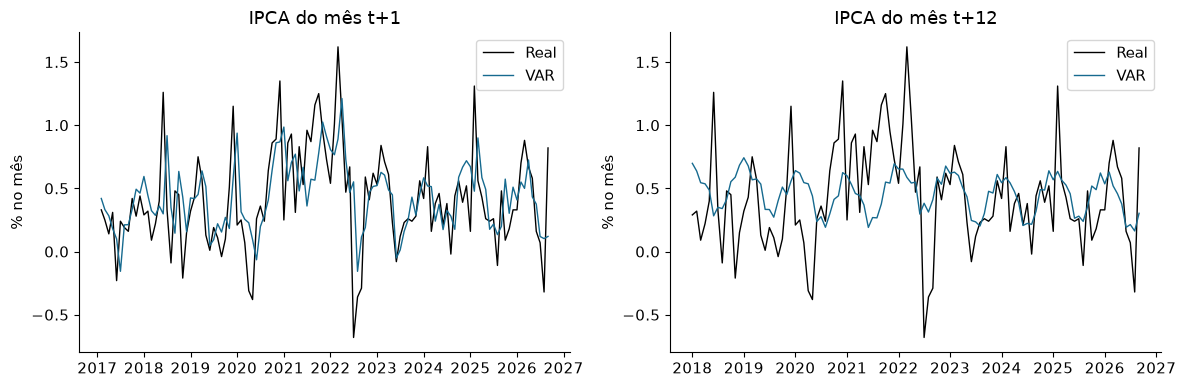

Pseudo fora da amostra: séries atuais/revisadas, sem reconstruir vintages/calendário de divulgação.
Sem dados posteriores à origem na estimação. DM: VAR vs sazonal, bilateral; CW: VAR vs AR, unilateral.
RW é referência descritiva. AR é aninhado no VAR; não interpretar DM entre eles.


### A8. Síntese e arquivos para a apresentação

Brent: aumento na resposta acumulada do IPCA em h=12, nesta especificação.
Cambio: redução na resposta acumulada do IPCA em h=12, nesta especificação. Magnitude e banda instáveis entre especificações: não é efeito estrutural da depreciação.
Brent no mês do choque: -0.005 p.p. antes e +0.145 depois; correlação das surpresas Brent-IPCA -0.02 e +0.42.
Brent em 13 especificações: positiva em 13, de 0.20 a 0.38 p.p.; banda exclui zero em 10.
Antes/depois é associação entre regimes. Pandemia, tributos, composição de choques e 2023 também importam.
Tempo total: 61.4s. Resultados em resultados


In [5]:
# Anexo: demais exigências do desafio e síntese desta execução.
resumo = var.anexo(dados, modelo, regimes, diagnostico, choques, ident, tabela_variantes)